Loaded results_summary_all.csv (20 rows)
Saved heatmap_document.pdf + heatmap_document.png


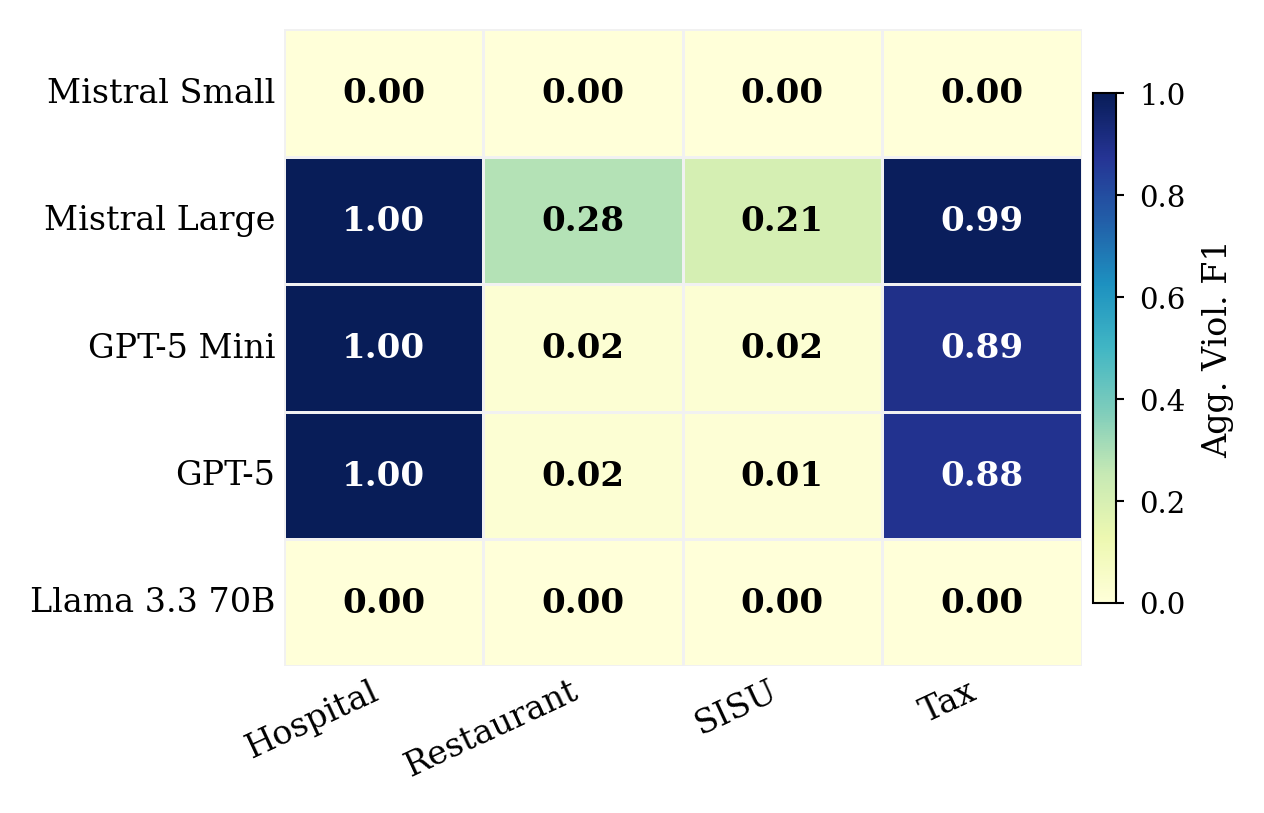

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

CSV_PATH = "results_summary_all.csv"

df = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH} ({len(df)} rows)")

# ── 1. Display names & orderings ──────────────────────────────────────────────
model_display = {
    "mistral-small-2506":      "Mistral Small",
    "mistral-large-2512":      "Mistral Large",
    "gpt-5-mini":              "GPT-5 Mini",
    "gpt-5":                   "GPT-5",
    "llama-3.3-70b-versatile": "Llama 3.3 70B",
}
dataset_display = {
    "hospital":   "Hospital",
    "restaurant": "Restaurant",
    "sisu":       "SISU",
    "tax":        "Tax",
}

# Desired visual order
model_order = [
    "mistral-small-2506",
    "mistral-large-2512",
    "gpt-5-mini",
    "gpt-5",
    "llama-3.3-70b-versatile",
]
dataset_order = ["hospital", "restaurant", "sisu", "tax"]

ordered_models = [model_display[m] for m in model_order]
ordered_datasets = [dataset_display[d] for d in dataset_order]

# ── 2. Publication-style rcParams ─────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":        "serif",
    "font.size":          9,
    "axes.titlesize":     10,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "text.usetex":        False,
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.6,
    "ytick.major.width":  0.6,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
})

CMAP = "YlGnBu"
METRIC = "aggregate_violation_f1"

# ── 3. Build heat matrix with explicit ordering ───────────────────────────────
df["model_d"] = df["model"].map(model_display)
df["dataset_d"] = df["dataset"].map(dataset_display)

# keep only rows we can display
df = df[df["model_d"].notna() & df["dataset_d"].notna()].copy()

heat_data = (
    df.pivot_table(
        index="model_d",
        columns="dataset_d",
        values=METRIC,
        aggfunc="mean"
    )
    .reindex(index=ordered_models, columns=ordered_datasets)
)

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

# ── 4. Figure layout ──────────────────────────────────────────────────────────
n_rows = len(ordered_models)
n_cols = len(ordered_datasets)

fig_w = 0.80 + n_cols * 0.95
fig_h = 0.55 + n_rows * 0.48

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.subplots_adjust(left=0.24, right=0.93, top=0.92, bottom=0.20)

# ── 5. Heatmap ────────────────────────────────────────────────────────────────
hm = sns.heatmap(
    heat_data,
    ax=ax,
    annot=False,
    cmap=CMAP,
    vmin=0.0,
    vmax=1.0,
    linewidths=0.25,
    linecolor="#f1f1f1",
    cbar=True,
    cbar_kws={"shrink": 0.80, "pad": 0.012, "aspect": 22},
    xticklabels=True,
    yticklabels=True,
)

# Best value per dataset column
col_max = heat_data.max(axis=0, skipna=True)

for i in range(heat_data.shape[0]):
    for j in range(heat_data.shape[1]):
        val = heat_data.iloc[i, j]
        label = _fmt(val)

        if pd.isna(val):
            txt_color = "#666666"
            fontweight = "normal"
        else:
            txt_color = "white" if val >= 0.55 else "black"
            fontweight = "bold" if pd.notna(col_max.iloc[j]) and val == col_max.iloc[j] else "semibold"

        ax.text(
            j + 0.5, i + 0.5, label,
            ha="center", va="center",
            fontsize=8.2,
            color=txt_color,
            fontweight=fontweight,
            family="serif",
        )

# ── 6. Colour-bar cosmetics ───────────────────────────────────────────────────
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=7, length=2, width=0.5)
cbar.set_label("Agg. Viol. F1", size=8, labelpad=4)
cbar.outline.set_linewidth(0.5)

# ── 7. Axis labels & ticks ────────────────────────────────────────────────────
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", fontsize=8)
ax.set_yticklabels(ordered_models, rotation=0, fontsize=8)
ax.tick_params(length=0, pad=2)

for spine in ax.spines.values():
    spine.set_visible(False)

# ── 8. Save ───────────────────────────────────────────────────────────────────
fig.savefig("document_mapping.pdf", format="pdf")
fig.savefig("document_mapping.png", format="png")
print("Saved document_mapping.pdf + document_mapping.png")
plt.show()